# 26. Molecular Featurization III: Fingerprints and Descriptors
@Shengli (Bruce) Jiang, University of South Carolina

## Imports

If needed, run `%pip install rdkit numpy pillow` once, then restart the kernel.

In [1]:
import numpy as np
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import Draw, MACCSkeys, rdFingerprintGenerator
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors, Crippen

In [2]:
draw_options = Draw.MolDrawOptions()
draw_options.useBWAtomPalette()
draw_options.legendFontSize = 18
draw_options.legendFraction = 0.20

print('RDKit:', rdBase.rdkitVersion)

RDKit: 2026.03.5


## SMILES

In [3]:
phenol = Chem.MolFromSmiles('Oc1ccccc1')

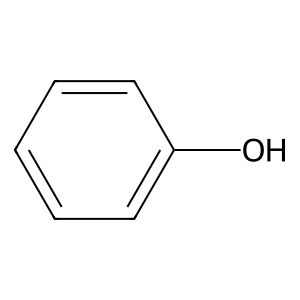

In [4]:
Draw.MolToImage(phenol, options=draw_options)

In [5]:
Chem.MolToSmiles(phenol)

'Oc1ccccc1'

### Atoms and Bonds

Indices start at zero. Hydrogens are implicit in this graph.

In [6]:
print('Atoms:', phenol.GetNumAtoms())
print('Bonds:', phenol.GetNumBonds())

Atoms: 7
Bonds: 7


In [7]:
atom = phenol.GetAtomWithIdx(0)
print('Element:', atom.GetSymbol())
print('Attached H:', atom.GetTotalNumHs())

Element: O
Attached H: 1


In [8]:
bond = phenol.GetBondWithIdx(0)
print('Bond type:', bond.GetBondType())
print('Atom indices:', bond.GetBeginAtomIdx(), bond.GetEndAtomIdx())

Bond type: SINGLE
Atom indices: 0 1


## Morgan Fingerprints

Radius 2 includes features generated at radii 0, 1, and 2.

In [9]:
morgan = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048, includeChirality=True,
)

In [10]:
morgan_fp = morgan.GetFingerprint(phenol)
len(morgan_fp)

2048

In [11]:
morgan_fp.GetNumOnBits()

11

## MACCS Keys

Each key tests a fixed chemical condition. The value is 1 if the condition is satisfied and 0 otherwise. RDKit stores 166 public keys in 167 positions; position 0 is unused.

| Key | Condition |
| --- | --- |
| 139 | At least one oxygen atom carrying a hydrogen (O–H) |
| 159 | At least two oxygen atoms |
| 162 | At least one aromatic atom |
| 164 | At least one oxygen atom |

In [12]:
maccs_fp = MACCSkeys.GenMACCSKeys(phenol)
len(maccs_fp)

167

In [13]:
maccs_fp[164]

1

In [14]:
maccs_fp[139]

1

In [15]:
maccs_fp[159]

0

In [16]:
maccs_fp[162]

1

In [17]:
catechol = Chem.MolFromSmiles('Oc1ccccc1O')

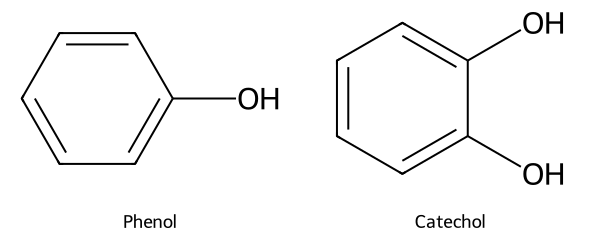

In [18]:
Draw.MolsToGridImage(
    [phenol, catechol], legends=['Phenol', 'Catechol'],
    molsPerRow=2, subImgSize=(300, 240), drawOptions=draw_options,
)

In [19]:
catechol_maccs = MACCSkeys.GenMACCSKeys(catechol)
catechol_maccs[159]

1

### Selected MACCS Keys

Phenol and anisole both contain oxygen. Only phenol has an O–H group.

Store the selected keys in a NumPy array, with one row per molecule.

In [20]:
smiles = {
    'Phenol': 'Oc1ccccc1',
    'Catechol': 'Oc1ccccc1O',
    'Anisole': 'COc1ccccc1',
    'p-Cresol': 'Cc1ccc(O)cc1',
    'Benzene': 'c1ccccc1',
    'Cyclohexanol': 'OC1CCCCC1',
}

In [21]:
molecules = {name: Chem.MolFromSmiles(s) for name, s in smiles.items()}
molecule_names = list(molecules)

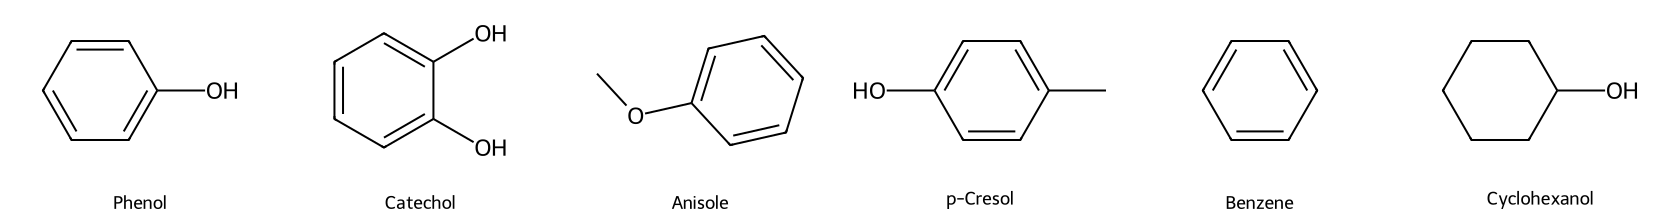

In [22]:
Draw.MolsToGridImage(
    list(molecules.values()), legends=list(molecules),
    molsPerRow=6, subImgSize=(280, 220), drawOptions=draw_options,
)

In [23]:
selected_keys = [139, 159, 162, 164]
key_rows = []
for mol in molecules.values():
    fingerprint = MACCSkeys.GenMACCSKeys(mol)
    key_rows.append([fingerprint[key] for key in selected_keys])

maccs_examples = np.array(key_rows, dtype=int)

print(f"{'Molecule':<14}" + ''.join(f'{key:>6}' for key in selected_keys))
for name, row in zip(molecule_names, maccs_examples):
    print(f'{name:<14}' + ''.join(f'{value:>6d}' for value in row))

Molecule         139   159   162   164
Phenol             1     0     1     1
Catechol           1     1     1     1
Anisole            0     0     1     1
p-Cresol           1     0     1     1
Benzene            0     0     1     0
Cyclohexanol       1     0     0     1


Phenol and p-cresol agree on these four keys. Their full MACCS fingerprints differ.

## RDKit Fingerprints

These settings enumerate connected fragments containing 1–7 bonds, including branches. Each fragment is hashed to two bit positions. Fragment size counts bonds, not a radius.

In [24]:
path = rdFingerprintGenerator.GetRDKitFPGenerator(
    minPath=1, maxPath=7, fpSize=2048,
    branchedPaths=True, numBitsPerFeature=2,
)

In [25]:
bit_info = rdFingerprintGenerator.AdditionalOutput()
bit_info.AllocateBitPaths()

In [26]:
rdkit_fp = path.GetFingerprint(phenol, additionalOutput=bit_info)
len(rdkit_fp)

2048

In [27]:
bit_paths = bit_info.GetBitPaths()
bit_paths[1371]

((0,),)

In [28]:
bit_paths[1400]

((0,),)

### Highlighted Fragments

`GetBitPaths()` records the bond indices that activated each bit. Bond 0 joins oxygen to a ring carbon and activates bits 1371 and 1400. The drawings use the first recorded fragment for each labeled bit.

In [29]:
fragment_options = Draw.MolDrawOptions()
fragment_options.useBWAtomPalette()
fragment_options.setHighlightColour((0.70, 0.85, 1.0))
fragment_options.setBondNoteColour((0, 0, 0))
fragment_options.addBondIndices = True
fragment_options.legendFontSize = 18
fragment_options.legendFraction = 0.20

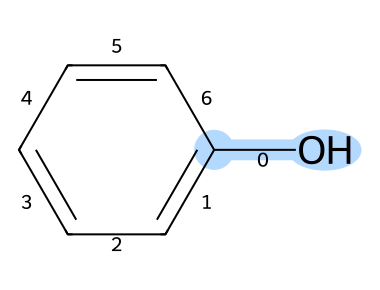

In [30]:
Draw.MolToImage(
    phenol, size=(380, 290),
    highlightAtoms=[0, 1], highlightBonds=[0],
    options=fragment_options,
)

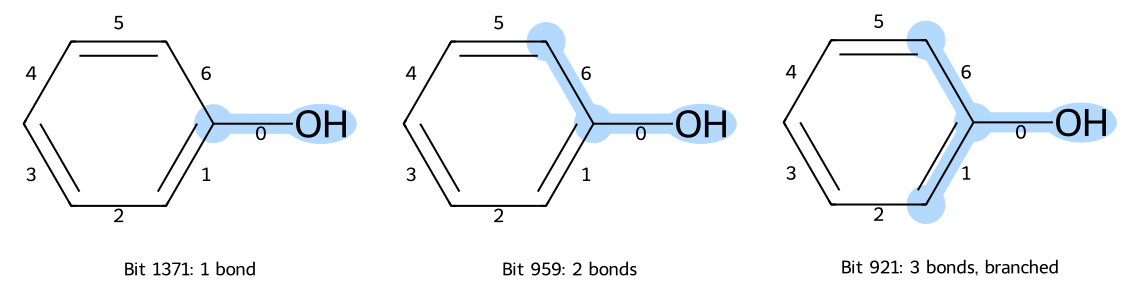

In [31]:
Draw.MolsToGridImage(
    [phenol, phenol, phenol],
    legends=['Bit 1371: 1 bond', 'Bit 959: 2 bonds', 'Bit 921: 3 bonds, branched'],
    molsPerRow=3, subImgSize=(380, 290),
    highlightAtomLists=[[0, 1], [0, 1, 6], [0, 1, 2, 6]],
    highlightBondLists=[[0], [0, 6], [0, 1, 6]],
    drawOptions=fragment_options,
)

In [32]:
example_bit_pairs = [(1371, 1400), (959, 1342), (921, 954)]

print(f"{'Bit positions':<18}{'Bond indices':<18}{'Bond count':>10}")
for bit_pair in example_bit_pairs:
    bond_indices = list(bit_paths[bit_pair[0]][0])
    print(f'{str(list(bit_pair)):<18}{str(bond_indices):<18}{len(bond_indices):>10}')

Bit positions     Bond indices      Bond count
[1371, 1400]      [0]                        1
[959, 1342]       [0, 6]                     2
[921, 954]        [0, 6, 1]                  3


Repeated occurrences of a fragment activate the same bits. Hash collisions can also assign different fragments to the same bit. Bit numbers depend on the fingerprint settings.

## Tanimoto Similarity

Each pair must use the same fingerprint family and settings.

In [33]:
DataStructs.TanimotoSimilarity(maccs_fp, catechol_maccs)

0.625

## Fingerprint Comparison

Compare each molecule with phenol using the three fingerprint families.

In [34]:
candidates = {name: mol for name, mol in molecules.items() if name != 'Phenol'}
candidate_names = list(candidates)
fingerprint_names = ['Morgan', 'MACCS', 'RDKit']

rows = []
for mol in candidates.values():
    morgan_score = DataStructs.TanimotoSimilarity(
        morgan_fp, morgan.GetFingerprint(mol))
    maccs_score = DataStructs.TanimotoSimilarity(
        maccs_fp, MACCSkeys.GenMACCSKeys(mol))
    path_score = DataStructs.TanimotoSimilarity(
        rdkit_fp, path.GetFingerprint(mol))
    rows.append([morgan_score, maccs_score, path_score])

comparison = np.array(rows)

print(f"{'Molecule':<14}" + ''.join(f'{name:>10}' for name in fingerprint_names))
for name, row in zip(candidate_names, comparison):
    print(f'{name:<14}' + ''.join(f'{score:>10.3f}' for score in row))

Molecule          Morgan     MACCS     RDKit
Catechol           0.500     0.625     0.667
Anisole            0.316     0.692     0.594
p-Cresol           0.412     0.909     0.507
Benzene            0.273     0.300     0.316
Cyclohexanol       0.048     0.444     0.000


## Molecular Descriptors

Descriptors summarize selected molecular properties as numbers.

| Descriptor | Meaning |
| --- | --- |
| MW | Average molar mass (g mol⁻¹) |
| HBD | Number of hydrogen-bond donor sites |
| HBA | Number of hydrogen-bond acceptor sites |
| TPSA | Topological polar surface area (Å²) |
| MolLogP | Calculated octanol/water logP |

### Molar Mass

`MolWt()` includes implicit hydrogens and uses average atomic weights.

In [35]:
round(Descriptors.MolWt(phenol), 3)
Descriptors.NumHDonors(phenol)

1

### Hydrogen-Bond Donors and Acceptors

A donor contains a suitable X–H group. An acceptor has an available lone pair.

In [36]:
Lipinski.NumHDonors(phenol)

1

In [37]:
Lipinski.NumHAcceptors(phenol)

1

### Topological Polar Surface Area

TPSA uses atom-environment contributions and requires no 3D conformer. RDKit includes nitrogen and oxygen contributions by default.

In [38]:
rdMolDescriptors.CalcTPSA(phenol)

20.23

In [39]:
rdMolDescriptors.CalcTPSA(catechol)

40.46

### Calculated logP

For a neutral solute at equilibrium,

$$P=\frac{c_{\mathrm{octanol}}}{c_{\mathrm{water}}},\qquad \log P=\log_{10}P.$$

Here, $c$ is the solute concentration in each liquid phase. RDKit estimates logP from atomic contributions.

In [40]:
round(Crippen.MolLogP(benzene), 4)

NameError: name 'benzene' is not defined

## Descriptor Vectors

Store each molecule's descriptors in a NumPy array. Use the same order for every molecule, `[MW, HBD, HBA, TPSA, MolLogP]`.

In [ ]:
descriptor_names = ['MW', 'HBD', 'HBA', 'TPSA', 'MolLogP']

def descriptor_row(mol):
    return np.array([
        Descriptors.MolWt(mol),
        Lipinski.NumHDonors(mol),
        Lipinski.NumHAcceptors(mol),
        rdMolDescriptors.CalcTPSA(mol),
        Crippen.MolLogP(mol),
    ], dtype=float)

In [ ]:
phenol_descriptors = descriptor_row(phenol)
print(descriptor_names)
np.round(phenol_descriptors, 2)

## Descriptor Matrix

Stack the vectors into a matrix. Rows follow `molecule_names`; columns follow `descriptor_names`. Keep the full precision in `X` and round only the displayed values.

In [ ]:
X = np.vstack([descriptor_row(mol) for mol in molecules.values()])

print(f"{'Molecule':<14}" + ''.join(f'{name:>10}' for name in descriptor_names))
for name, row in zip(molecule_names, X):
    print(
        f'{name:<14}{row[0]:>10.2f}{row[1]:>10.0f}{row[2]:>10.0f}'
        f'{row[3]:>10.2f}{row[4]:>10.2f}'
    )

In [ ]:
X.shape

## Positional Isomers

Compare catechol and hydroquinone. `np.allclose()` checks whether their descriptor vectors agree within a small numerical tolerance.

In [ ]:
hydroquinone = Chem.MolFromSmiles('Oc1ccc(O)cc1')

In [ ]:
Draw.MolsToGridImage(
    [catechol, hydroquinone], legends=['Catechol (1,2)', 'Hydroquinone (1,4)'],
    molsPerRow=2, subImgSize=(320, 240), drawOptions=draw_options,
)

In [ ]:
isomer_names = ['Catechol', 'Hydroquinone']
isomer_descriptors = np.vstack([
    descriptor_row(catechol),
    descriptor_row(hydroquinone),
])

print(f"{'Molecule':<14}" + ''.join(f'{name:>10}' for name in descriptor_names))
for name, row in zip(isomer_names, isomer_descriptors):
    print(
        f'{name:<14}{row[0]:>10.4f}{row[1]:>10.0f}{row[2]:>10.0f}'
        f'{row[3]:>10.4f}{row[4]:>10.4f}'
    )

In [ ]:
np.allclose(isomer_descriptors[0], isomer_descriptors[1])

These five descriptors do not distinguish catechol from hydroquinone.

## Resorcinol

Compare resorcinol with catechol using their descriptor vectors and Morgan fingerprints.

In [ ]:
resorcinol = Chem.MolFromSmiles('Oc1cccc(O)c1')

In [ ]:
Draw.MolToImage(resorcinol, options=draw_options)

In [ ]:
resorcinol_descriptors = descriptor_row(resorcinol)
print(descriptor_names)
np.round(resorcinol_descriptors, 4)

In [ ]:
np.allclose(resorcinol_descriptors, descriptor_row(catechol))

In [ ]:
resorcinol_fp = morgan.GetFingerprint(resorcinol)
catechol_fp = morgan.GetFingerprint(catechol)
DataStructs.TanimotoSimilarity(catechol_fp, resorcinol_fp)